# 97.88% of Eligible Product Views Did Not Reach Cart

## Customer Journey and Retention Analysis

Retailrocket event data | SQL, Python and statistical inference

**Business question:** Where does the observed product journey lose the most visitors, and which early behavior is associated with returning?

The funnel measures unique visitor-item pairs, while retention measures visitors. These are different denominators.

Run all cells from top to bottom with `Data/events.csv` available. The notebook rebuilds the derived SQLite tables and saves four charts in `figures/`. The source CSV is unchanged.


## 1. Load events

Timestamps are Unix milliseconds, converted to UTC. Anonymous visitor IDs represent observed browsers/visitors, not verified people or registered customers.

In [1]:
from pathlib import Path
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels

data_path = Path("Data") / "events.csv"

events = pd.read_csv(
    data_path,
    dtype={
        "timestamp": "int64",
        "visitorid": "int64",
        "event": "category",
        "itemid": "int64",
        "transactionid": "Int64"
    }
)

events["event_time"] = pd.to_datetime(
    events["timestamp"], unit="ms", utc=True
)

print(f"Rows: {len(events):,}")
print(f"Start: {events['event_time'].min()}")
print(f"End: {events['event_time'].max()}")
print(f"statsmodels: {statsmodels.__version__}")

display(events.head())

Rows: 2,756,101
Start: 2015-05-03 03:00:04.384000+00:00
End: 2015-09-18 02:59:47.788000+00:00
statsmodels: 0.15.0


,timestamp,visitorid,event,itemid,transactionid,event_time
0,1433221332117,257597,view,355908,<NA>,2015-06-02 05:02:12.117+00:00
1,1433224214164,992329,view,248676,<NA>,2015-06-02 05:50:14.164+00:00
2,1433221999827,111016,view,318965,<NA>,2015-06-02 05:13:19.827+00:00
3,1433221955914,483717,view,253185,<NA>,2015-06-02 05:12:35.914+00:00
4,1433221337106,951259,view,367447,<NA>,2015-06-02 05:02:17.106+00:00


## 2. Check data quality

Missing transaction IDs are expected for views and cart events.

In [2]:
required = ["timestamp", "visitorid", "event", "itemid"]
original = required + ["transactionid"]

print("Missing required values:")
print(events[required].isna().sum())

print(f"\nExact duplicate rows: {events.duplicated(subset=original).sum():,}")

print("\nEvent counts:")
print(events["event"].value_counts())

print("\nPurchase events missing transactionid:")
print(
    events.loc[
        events["event"] == "transaction", "transactionid"
    ].isna().sum()
)

Missing required values:
timestamp    0
visitorid    0
event        0
itemid       0
dtype: int64

Exact duplicate rows: 460

Event counts:
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64

Purchase events missing transactionid:
0


### Data cleaning

Removed 460 exact duplicate rows across the five original columns,
keeping one copy of each. This assumes identical records are duplicate
logs; the dataset does not prove this. The source CSV remains unchanged.

In [3]:
events_clean = events.drop_duplicates(subset=original).copy()

print(f"Rows after cleaning: {len(events_clean):,}", flush=True)
print("Loading SQLite...", flush=True)

conn = sqlite3.connect(Path("Data") / "customer_journey.db")

events_clean[original].to_sql(
    "events",
    conn,
    if_exists="replace",
    index=False,
    chunksize=10000
)

print("Creating index...", flush=True)

conn.execute("""
    CREATE INDEX idx_events_visitor_item_time
    ON events (visitorid, itemid, timestamp)
""")
conn.commit()

print("Ready: Data/customer_journey.db")

Rows after cleaning: 2,755,641
Loading SQLite...
Creating index...
Ready: Data/customer_journey.db


### Check the SQLite import

Confirm that nullable transaction IDs were written as SQL NULL.

In [5]:
pd.read_sql_query("""
    SELECT
        event,
        COUNT(*) AS total_rows,
        SUM(transactionid IS NULL) AS missing_transaction_id,
        SUM(transactionid IS NOT NULL) AS present_transaction_id
    FROM events
    GROUP BY event
""", conn)

,event,total_rows,missing_transaction_id,present_transaction_id
0,addtocart,68966,68966,0
1,transaction,22457,0,22457
2,view,2664218,2664218,0


## 3. Ordered purchase funnel

Entry is the first observed view for each visitor-item pair, at least 14 elapsed days before the last observed event. A cart must be strictly later than that view and within 7 elapsed days; a purchase must be strictly later than its cart and within another 7 days. Upper boundaries are inclusive. Equal timestamps do not establish order.

For repeated carts, select the earliest valid cart with a qualifying purchase, otherwise the earliest valid cart. Each pair is counted once. View-to-cart divides by eligible viewed pairs; cart-to-purchase divides by their cart pairs. Purchases without this observed sequence are outside this funnel.

**Result:** 1,938,845 eligible pairs, 41,100 reaching cart, and 14,816 reaching purchase. The largest observed drop-off is view-to-cart: 97.88%. This identifies an investigation priority, not a diagnosed UX defect.


In [6]:
print("Building funnel...", flush=True)

conn.executescript("""
DROP TABLE IF EXISTS funnel_pairs;

CREATE TABLE funnel_pairs AS
WITH first_views AS (
    SELECT
        visitorid,
        itemid,
        MIN(timestamp) AS view_time
    FROM events
    WHERE event = 'view'
    GROUP BY visitorid, itemid
    HAVING MIN(timestamp) <= (
        SELECT MAX(timestamp) - 1209600000
        FROM events
    )
),
cart_matches AS (
    SELECT
        v.visitorid,
        v.itemid,
        v.view_time,
        c.timestamp AS cart_time,
        (
            SELECT MIN(p.timestamp)
            FROM events AS p
            WHERE p.visitorid = v.visitorid
              AND p.itemid = v.itemid
              AND p.event = 'transaction'
              AND p.timestamp > c.timestamp
              AND p.timestamp <= c.timestamp + 604800000
        ) AS purchase_time
    FROM first_views AS v
    LEFT JOIN events AS c
        ON c.visitorid = v.visitorid
       AND c.itemid = v.itemid
       AND c.event = 'addtocart'
       AND c.timestamp > v.view_time
       AND c.timestamp <= v.view_time + 604800000
)
SELECT
    visitorid,
    itemid,
    view_time,
    COALESCE(
        MIN(CASE WHEN purchase_time IS NOT NULL THEN cart_time END),
        MIN(cart_time)
    ) AS cart_time,
    MIN(purchase_time) AS purchase_time
FROM cart_matches
GROUP BY visitorid, itemid, view_time;
""")

funnel = pd.read_sql_query("""
    SELECT
        COUNT(*) AS viewed_pairs,
        COUNT(cart_time) AS cart_pairs,
        COUNT(purchase_time) AS purchased_pairs
    FROM funnel_pairs
""", conn)

views, carts, purchases = map(int, funnel.iloc[0])

display(funnel)
print(f"View → Cart: {carts / views:.2%}")
print(f"Cart → Purchase: {purchases / carts:.2%}")
print(f"View → Purchase: {purchases / views:.2%}")

Building funnel...


,viewed_pairs,cart_pairs,purchased_pairs
0,1938845,41100,14816


View → Cart: 2.12%
Cart → Purchase: 36.05%
View → Purchase: 0.76%


### Funnel chart

Bar labels show the percentage of all eligible viewed pairs, not conversion from the preceding stage.

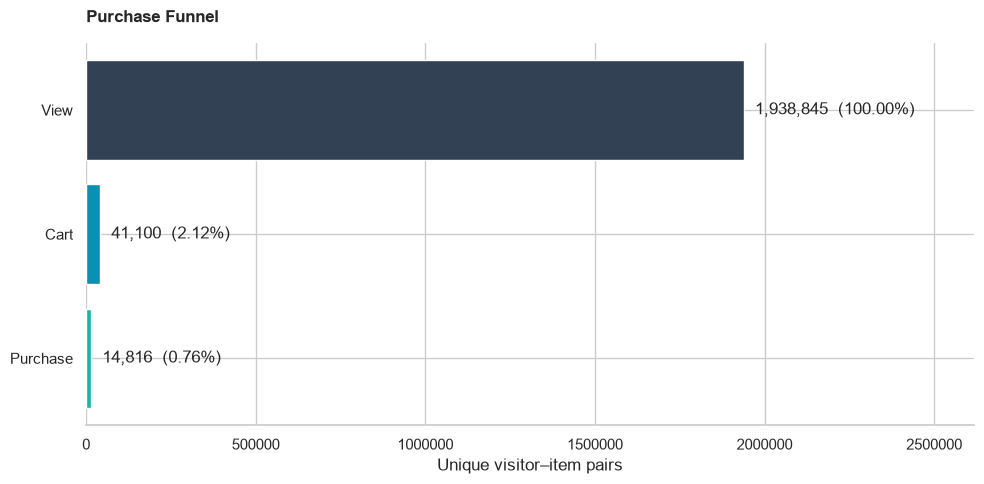

In [7]:
sns.set_theme(style="whitegrid", context="notebook")
figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 5))

counts = [views, carts, purchases]
bars = ax.barh(
    ["View", "Cart", "Purchase"],
    counts,
    color=["#334155", "#0891B2", "#14B8A6"]
)

ax.invert_yaxis()
ax.bar_label(
    bars,
    labels=[f"{n:,}  ({n / views:.2%})" for n in counts],
    padding=8
)
ax.set_xlim(0, views * 1.35)
ax.set_xlabel("Unique visitor–item pairs")
ax.set_title("Purchase Funnel", loc="left", fontweight="bold", pad=15)
ax.ticklabel_format(style="plain", axis="x")
sns.despine(left=True)
fig.tight_layout()
fig.savefig(figures_dir / "01_purchase_funnel.png", dpi=200)
plt.show()

## 4. Weekly stage conversion

Group by the Monday UTC week of first view. Keep only full entry weeks entirely inside the eligible period. The overall funnel includes eligible pairs in boundary weeks; this weekly chart excludes partial entry weeks.

**Result:** View-to-cart conversion was lower than cart-to-purchase in all 17 eligible full weeks, from 2015-05-04 through 2015-08-24. Drop-off is one minus each step conversion rate.


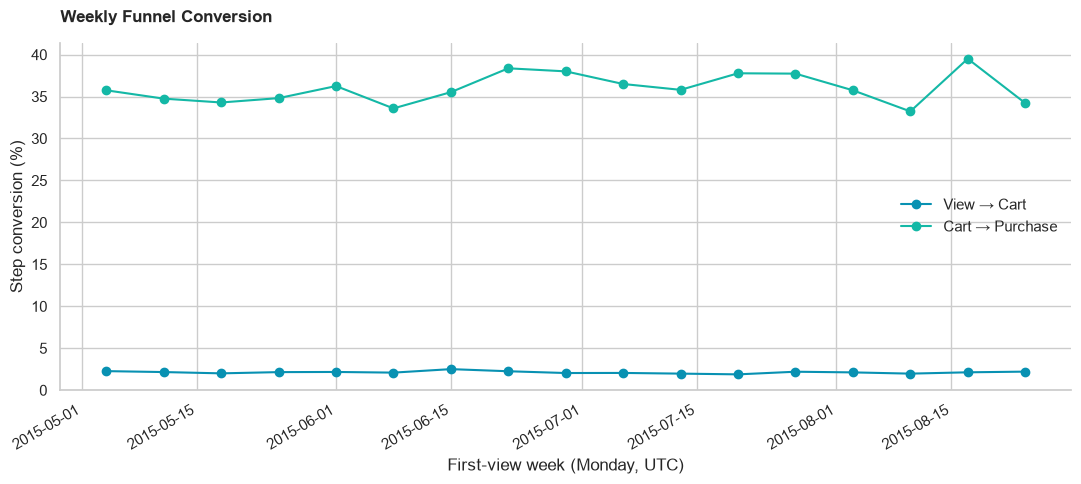

Complete eligible weeks: 17
Weeks with lower View → Cart conversion: 17


In [8]:
weekly = pd.read_sql_query("""
    SELECT
        date(
            view_time / 1000.0, 'unixepoch',
            '-6 days', 'weekday 1'
        ) AS week_start,
        COUNT(*) AS viewed_pairs,
        COUNT(cart_time) AS cart_pairs,
        COUNT(purchase_time) AS purchased_pairs
    FROM funnel_pairs
    GROUP BY week_start
    ORDER BY week_start
""", conn)

weekly["week_start"] = pd.to_datetime(weekly["week_start"], utc=True)

data_start = events_clean["event_time"].min()
data_end = events_clean["event_time"].max()

weekly = weekly.loc[
    (weekly["week_start"] >= data_start)
    & (
        weekly["week_start"] + pd.Timedelta(days=7)
        <= data_end - pd.Timedelta(days=14)
    )
].copy()

weekly["view_to_cart"] = weekly["cart_pairs"] / weekly["viewed_pairs"]
weekly["cart_to_purchase"] = (
    weekly["purchased_pairs"]
    / weekly["cart_pairs"].replace(0, float("nan"))
)

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    weekly["week_start"], weekly["view_to_cart"] * 100,
    marker="o", color="#0891B2", label="View → Cart"
)
ax.plot(
    weekly["week_start"], weekly["cart_to_purchase"] * 100,
    marker="o", color="#14B8A6", label="Cart → Purchase"
)

ax.set_title(
    "Weekly Funnel Conversion",
    loc="left", fontweight="bold", pad=15
)
ax.set_xlabel("First-view week (Monday, UTC)")
ax.set_ylabel("Step conversion (%)")
ax.set_ylim(bottom=0)
ax.legend(frameon=False)
sns.despine()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(figures_dir / "02_weekly_conversion.png", dpi=200)
plt.show()

print(f"Complete eligible weeks: {len(weekly)}")
print(
    "Weeks with lower View → Cart conversion:",
    int((weekly["view_to_cart"] < weekly["cart_to_purchase"]).sum())
)

## 5. Weekly cohort retention

Cohort = Monday week of the visitor's first observed event of any kind. A visitor is active in a later week if any event is recorded then. Each visitor counts at most once in a cohort-week cell; the denominator is the original cohort size. Week 0 is omitted from the chart.

Unfinished follow-up weeks are NaN, not zero. First observed activity is not necessarily acquisition. The 2015-04-27 cohort contains only activity observed from May 3 and is a partial entry cohort; its 9.5% week-1 figure should not be compared directly with full entry weeks. The last two rows have no complete later week yet.

**Finding:** The May 4 cohort's return rate fell from about 4.8% in week 1 to 2.8% in week 2 and 1.6% in week 4 (rounded chart values). These are returns in each separate calendar week, not cumulative retention.


Building weekly retention...


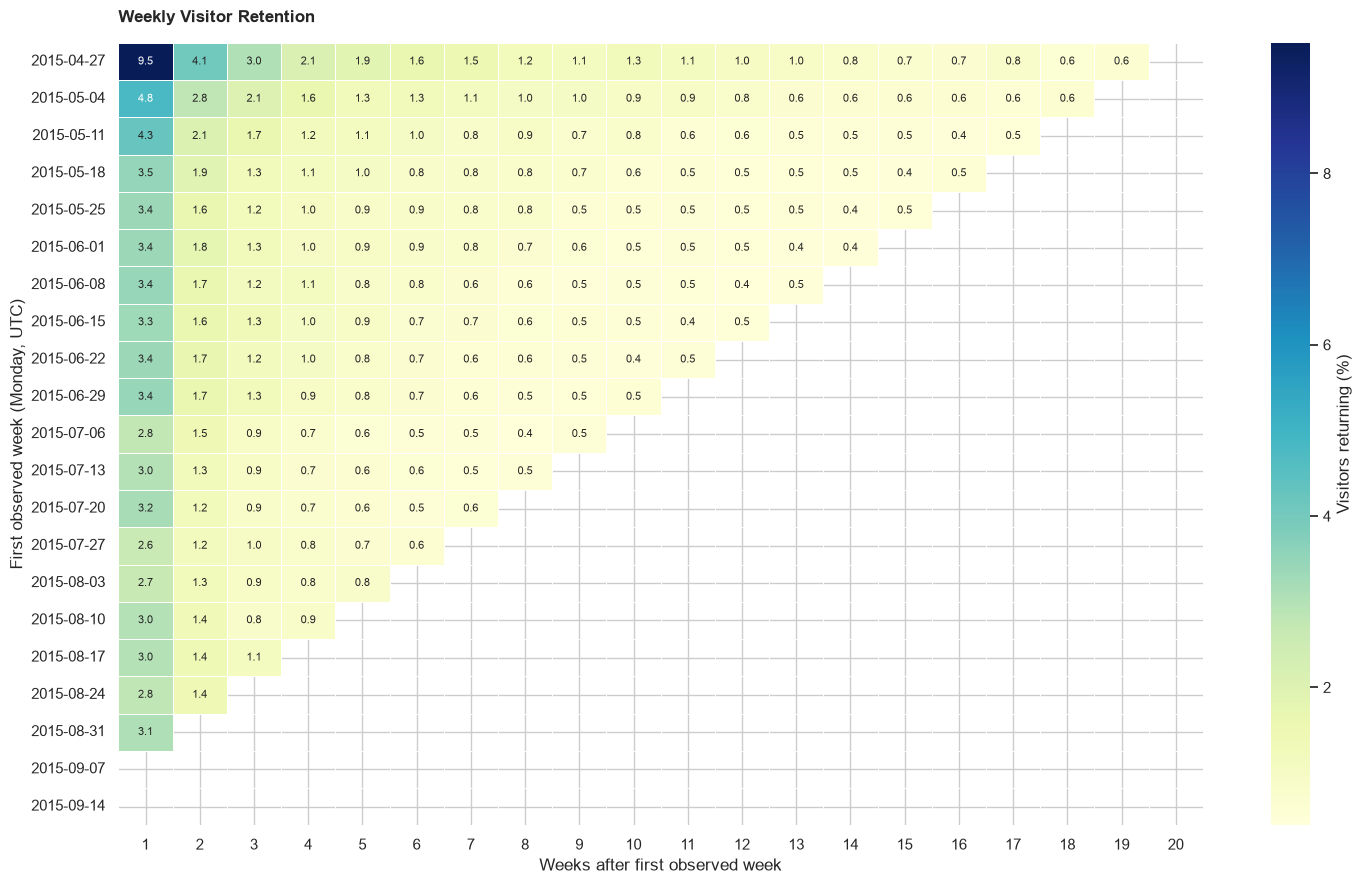

In [10]:
print("Building weekly retention...", flush=True)

activity = events_clean[["visitorid", "event_time"]].copy()

activity["activity_week"] = (
    activity["event_time"].dt.normalize()
    - pd.to_timedelta(activity["event_time"].dt.day_of_week, unit="D")
)

activity = activity[["visitorid", "activity_week"]].drop_duplicates()

first_week = activity.groupby("visitorid")["activity_week"].min()
activity["cohort_week"] = activity["visitorid"].map(first_week)

activity["week_number"] = (
    (activity["activity_week"] - activity["cohort_week"]).dt.days // 7
)

cohort_sizes = first_week.value_counts().sort_index()

cohort_counts = (
    activity.groupby(["cohort_week", "week_number"])
    .size()
    .unstack(fill_value=0)
)

max_week = int(activity["week_number"].max())

cohort_counts = cohort_counts.reindex(
    index=cohort_sizes.index,
    columns=range(max_week + 1),
    fill_value=0
)

retention = cohort_counts.div(cohort_sizes, axis=0)

data_end = events_clean["event_time"].max()

for week in retention.columns:
    week_end = retention.index + pd.Timedelta(weeks=week + 1)
    retention.loc[week_end > data_end, week] = float("nan")

heatmap_data = retention.drop(columns=0).copy()
heatmap_data.index = heatmap_data.index.strftime("%Y-%m-%d")

fig, ax = plt.subplots(figsize=(15, 9))

sns.heatmap(
    heatmap_data * 100,
    mask=heatmap_data.isna(),
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.4,
    cbar_kws={"label": "Visitors returning (%)"},
    annot_kws={"fontsize": 8},
    ax=ax
)

ax.set_title(
    "Weekly Visitor Retention",
    loc="left", fontweight="bold", pad=15
)
ax.set_xlabel("Weeks after first observed week")
ax.set_ylabel("First observed week (Monday, UTC)")
fig.tight_layout()
fig.savefig(figures_dir / "03_cohort_retention.png", dpi=200)
plt.show()

## 6. First-day cart activity and 7-day return

Group A added to cart on the same UTC calendar day as first observation. Group B did not, even if they added later. Outcome = any event during calendar days 1-7 after day 0. Require all seven follow-up days to finish before September 18, the final partial UTC day. Eligible first days end on September 10.

Compare independent visitor-level proportions using a two-sided pooled z-test and a 95% Newcombe confidence interval for A minus B. Observed return/non-return counts must be at least 10 in each group. This is an observational comparison, not a randomized A/B test.

**Result:** A: 4,623 / 30,761 (15.03%); B: 74,108 / 1,315,712 (5.63%). Difference: +9.40 percentage points, 95% CI [9.00, 9.80], p < 0.001. Selection bias, anonymous IDs and unmeasured differences limit causal interpretation.


In [11]:
from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep
)

first_day = (
    events_clean.groupby("visitorid")["event_time"]
    .min()
    .dt.normalize()
)

day_number = (
    events_clean["event_time"].dt.normalize()
    - events_clean["visitorid"].map(first_day)
).dt.days

day0_cart_ids = events_clean.loc[
    (events_clean["event"] == "addtocart") & (day_number == 0),
    "visitorid"
].unique()

return_ids = events_clean.loc[
    day_number.between(1, 7),
    "visitorid"
].unique()

visitors = first_day.to_frame("first_day")
visitors["day0_cart"] = visitors.index.isin(day0_cart_ids)
visitors["returned"] = visitors.index.isin(return_ids)

coverage_end = events_clean["event_time"].max().normalize()

visitors = visitors.loc[
    visitors["first_day"] + pd.Timedelta(days=8) <= coverage_end
].copy()

return_summary = (
    visitors.groupby("day0_cart")["returned"]
    .agg(visitors="size", returned="sum")
    .reindex([True, False])
)

return_summary["return_rate"] = (
    return_summary["returned"] / return_summary["visitors"]
)
return_summary.index = ["A: Cart on day 0", "B: No cart on day 0"]

counts = return_summary["returned"].to_numpy(dtype=int)
totals = return_summary["visitors"].to_numpy(dtype=int)

if (counts < 10).any() or ((totals - counts) < 10).any():
    raise ValueError("Group counts are too small for this z-test.")

z_stat, p_value = proportions_ztest(
    counts, totals, value=0, alternative="two-sided"
)

ci_low, ci_high = confint_proportions_2indep(
    counts[0], totals[0],
    counts[1], totals[1],
    method="newcomb", compare="diff", alpha=0.05
)

difference_pp = (
    return_summary["return_rate"].iloc[0]
    - return_summary["return_rate"].iloc[1]
) * 100

display(return_summary.style.format({
    "visitors": "{:,.0f}",
    "returned": "{:,.0f}",
    "return_rate": "{:.2%}"
}))

print(f"Difference (A − B): {difference_pp:.2f} percentage points")
print(f"95% CI: [{ci_low * 100:.2f}, {ci_high * 100:.2f}] percentage points")
print(f"z-statistic: {z_stat:.2f}")
print("p-value: < 0.001" if p_value < 0.001 else f"p-value: {p_value:.3g}")

,visitors,returned,return_rate
A: Cart on day 0,"30,761","4,623",15.03%
B: No cart on day 0,"1,315,712","74,108",5.63%


Difference (A − B): 9.40 percentage points
95% CI: [9.00, 9.80] percentage points
z-statistic: 69.43
p-value: < 0.001


### Return-rate difference

The point is the observed difference; the line is its 95% confidence interval. Zero represents equal return rates.

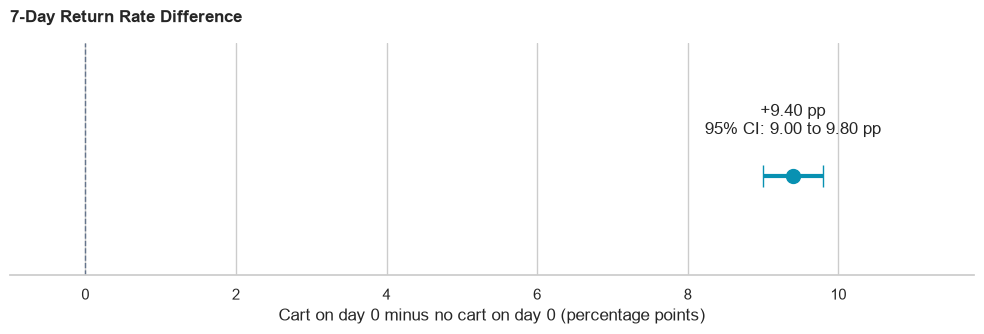

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.5))

ax.errorbar(
    difference_pp, 0,
    xerr=[
        [difference_pp - ci_low * 100],
        [ci_high * 100 - difference_pp]
    ],
    fmt="o",
    color="#0891B2",
    markersize=10,
    capsize=8,
    linewidth=3
)

ax.axvline(0, color="#64748B", linestyle="--", linewidth=1)
ax.set_yticks([])
ax.set_ylim(-0.6, 0.8)
ax.set_xlim(min(0, ci_low * 100) - 1, max(0, ci_high * 100) + 2)

ax.annotate(
    f"{difference_pp:+.2f} pp\n"
    f"95% CI: {ci_low * 100:.2f} to {ci_high * 100:.2f} pp",
    xy=(difference_pp, 0),
    xytext=(0, 30),
    textcoords="offset points",
    ha="center",
    fontsize=12
)

ax.set_title(
    "7-Day Return Rate Difference",
    loc="left", fontweight="bold", pad=15
)
ax.set_xlabel(
    "Cart on day 0 minus no cart on day 0 (percentage points)"
)

sns.despine(left=True)
fig.tight_layout()
fig.savefig(figures_dir / "04_return_rate_difference.png", dpi=200)
plt.show()

## Decisions and next actions

1. Investigate product-page and traffic quality before testing a view-to-cart change. Track pair-level cart conversion and downstream purchase conversion together.
2. Test a first-week return intervention using a randomized holdout. Use visitor-level days 1-7 return as the primary outcome and purchases as a guardrail.
3. Monitor visitors with and without first-day cart activity separately. The +9.40 pp observed difference is a segmentation signal, not a forecast of campaign lift.

See `reports/analysis_story.md` for the business narrative and `README.md` for setup, definitions and limitations. Source data is anonymized Retailrocket ecommerce activity from 2015; no Gulf-market representativeness is assumed.
